# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:
df = pd.read_csv("/content/cleaned_airbnb_data_7.csv")

print(df.shape)
df.head()

(4939, 85)


,id,listing_url,last_scraped,source,name,description,picture_url,host_id,host_url,host_profile_id,...,log_price,availability_365_minmax,number_of_reviews_zscore,review_group,price_per_person,long_term_stay,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,360,https://www.airbnb.com/rooms/360,2026-06-30,city scrape,Denver’s Peaceful Oasis for Travel Nurses & No...,Enjoy the famous Colorado weather and unplug i...,https://a0.muscache.com/pictures/monet/Select-...,666,https://www.airbnb.com/users/show/666,1462506156295946552,...,4.666736,0.909589,0.907760,High,53.175000,0,True,False,False,False
1,364,https://www.airbnb.com/rooms/364,2026-07-02,previous scrape,Lodo / RiNo LOFT via airport train,"Modern 1,000 square foot loft in the heart of ...",https://a0.muscache.com/pictures/11766413/a2c5...,783,https://www.airbnb.com/users/show/783,1462506164263986177,...,3.476614,0.980822,0.120787,High,10.783333,1,True,False,False,False
2,592,https://www.airbnb.com/rooms/592,2026-06-30,city scrape,private,This room is in the basement. It does not hav...,https://a0.muscache.com/pictures/ba522ff9-84c9...,933,https://www.airbnb.com/users/show/933,1462506173520460203,...,4.382027,0.605479,1.185983,High,40.000000,0,False,False,True,False
3,686,https://www.airbnb.com/rooms/686,2026-06-30,city scrape,Alexandra's Queen Bed Room Long-term Rental Only,Thanks for visiting my Queen Bed Room for LONG...,https://a0.muscache.com/pictures/108112/e6d5d3...,990,https://www.airbnb.com/users/show/990,1462506177119173037,...,3.790307,0.405479,1.432408,High,44.270000,1,False,False,True,False
4,1940,https://www.airbnb.com/rooms/1940,2026-06-30,city scrape,"Baker Studio Pet-friendly, Walkable, Patio",Private studio retreat in a charming historic ...,https://a0.muscache.com/pictures/miso/Hosting-...,2150,https://www.airbnb.com/users/show/2150,1462506289316853263,...,5.256036,0.898630,1.639088,High,95.860000,0,True,False,False,False


### Reflection: 
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. It's Denver Airbnb listings. It has host info (like how long they've been a host and how many listings they have), listing details (room type, how many people it fits, bedrooms, bathrooms, price, minimum nights), location, availability, and reviews. It also has the columns I added in Assignment 7, like price_per_person and long_term_stay.

2. 4,939 rows and 85 columns.


## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [3]:
keep = ['price', 'accommodates', 'bedrooms', 'beds', 'bathrooms', 'minimum_nights', 'availability_365',
        'number_of_reviews', 'review_scores_rating', 'long_term_stay',
        'room_type_Entire home/apt', 'room_type_Private room', 'room_type_Hotel room']
df = df[keep]

df = df.dropna()
df = df[df['price'] < 1000]
print(df.shape)

(3344, 13)


### Reflection: 
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. This dataset doesn't have post_id, title, descr, details, or address, so I dropped the Airbnb versions instead. I only kept 13 columns. The rest were IDs, URLs, text like the name and description, and dates, which a regression can't use. I also dropped columns made from price, like log_price, price_per_person, and estimated revenue. Then I removed rows with missing values and prices of 1,000 or more, which left 3,344 rows.

2. IDs and text would just add noise. The columns made from price would be cheating, since the model would basically be told the answer, so the score would look great but be useless for a new listing.


## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

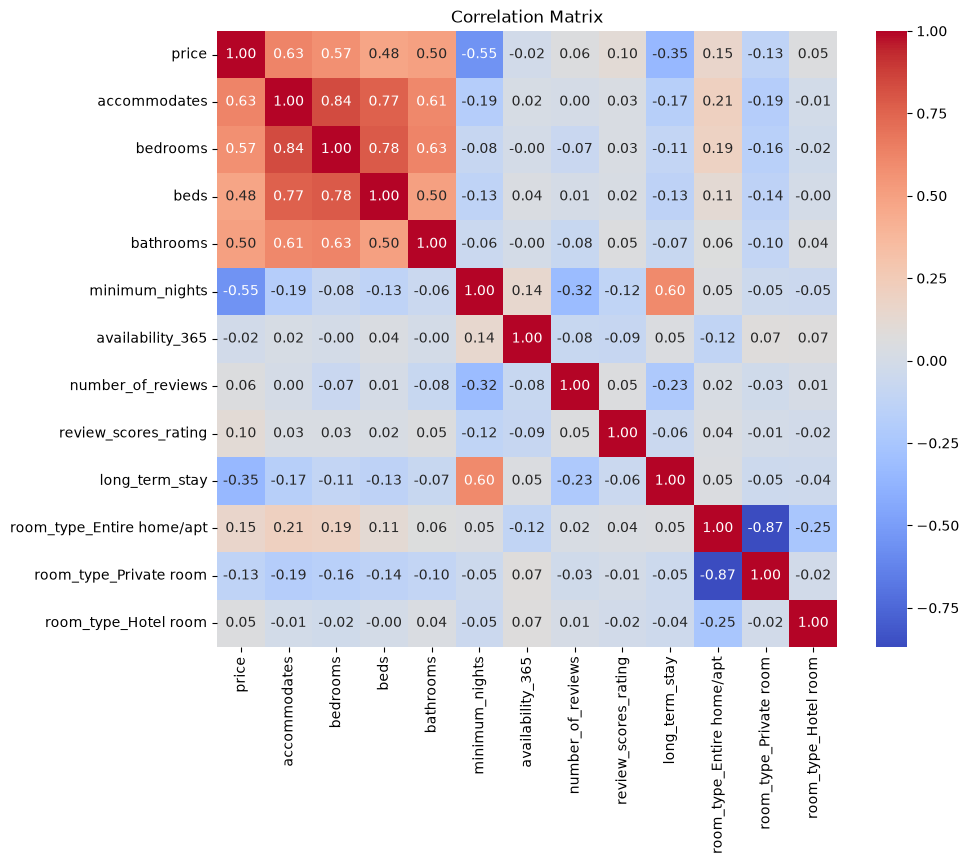

price                        1.000000
accommodates                 0.626399
bedrooms                     0.572456
bathrooms                    0.497640
beds                         0.480591
room_type_Entire home/apt    0.154809
review_scores_rating         0.104370
number_of_reviews            0.055574
room_type_Hotel room         0.054444
availability_365            -0.021617
room_type_Private room      -0.126829
long_term_stay              -0.348526
minimum_nights              -0.548388
Name: price, dtype: float64

In [4]:
corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

corr['price'].sort_values(ascending=False)

### Reflection: 
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. Accommodates had the strongest positive correlation (0.63), then bedrooms (0.57), bathrooms (0.50), and beds (0.48). The strongest negative was minimum_nights (-0.55), then long_term_stay (-0.35). So bigger places cost more, and places that require long stays charge less per night.

2. Accommodates, bedrooms, bathrooms, and minimum_nights look like the best ones. Room type could help too. availability_365 and number_of_reviews are close to 0, so they probably won't help much.


## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [5]:
y = df['price']
X = df.drop(columns=['price'])

X.columns

Index(['accommodates', 'bedrooms', 'beds', 'bathrooms', 'minimum_nights',
       'availability_365', 'number_of_reviews', 'review_scores_rating',
       'long_term_stay', 'room_type_Entire home/apt', 'room_type_Private room',
       'room_type_Hotel room'],
      dtype='object')

### Reflection: 
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. accommodates, bedrooms, beds, bathrooms, minimum_nights, availability_365, number_of_reviews, review_scores_rating, long_term_stay, and three room type columns (entire home, private room, and hotel room). Shared room is left out so the other three are compared to it.

2. Price is a number that can be anything, like 85 or 240, and we're trying to predict that exact amount. Classification would be for picking a group, like "cheap" or "expensive."


## 5. Split Data into Training and Testing Sets

### Business framing: 
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

## 6. Fit a Linear Regression Model

### Business framing: 
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [8]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R2:", r2)

MSE: 8995.55507082521
R2: 0.6559633426452758


### Reflection: 
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. The R² is about 0.66, so the model explains about 66% of the differences in price. That's decent for just a few basic features, but a lot is still unexplained.

2. The MSE is about 8,996. That sounds big, but it's in squared dollars, so the predictions are off by around 95 dollars a night on average. That's a lot for listings that are usually under 300. Adding location, like neighborhood, and amenities would probably help, since those matter a lot for price.


## 8. Interpret Model Coefficients

### Business framing: 
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top 

In [9]:
coef_table = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_})
coef_table['abs_coefficient'] = coef_table['coefficient'].abs()

coef_table.sort_values('abs_coefficient', ascending=False)

,feature,coefficient,abs_coefficient
11,room_type_Hotel room,201.200755,201.200755
9,room_type_Entire home/apt,145.145453,145.145453
10,room_type_Private room,103.891417,103.891417
3,bathrooms,38.296628,38.296628
1,bedrooms,29.789178,29.789178
0,accommodates,16.692316,16.692316
7,review_scores_rating,13.095623,13.095623
4,minimum_nights,-6.365216,6.365216
8,long_term_stay,6.129785,6.129785
2,beds,-3.578763,3.578763


### Reflection: 
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Room type had the biggest effect. Compared to a shared room, a hotel room adds about 201 dollars, an entire home about 145, and a private room about 104. After that, each extra bathroom adds about 38 dollars and each bedroom about 30.

2. Beds was slightly negative (about -3.6). I think that's because bedrooms and accommodates already cover size, so an extra bed with everything else the same might mean a more crowded room. long_term_stay was positive here even though it was negative in the correlation, which was weird.

3. The type of space and number of bathrooms and bedrooms matter way more than reviews or availability. A host can't change much except maybe adding a bathroom or listing the whole place instead of a room.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [10]:
top_features = coef_table.sort_values('abs_coefficient', ascending=False)['feature'].head(5)

model2 = LinearRegression()
model2.fit(X_train[top_features], y_train)
y_pred2 = model2.predict(X_test[top_features])

print("Baseline MSE:", mse, " R2:", r2)
print("Refined MSE:", mean_squared_error(y_test, y_pred2), " R2:", r2_score(y_test, y_pred2))

Baseline MSE: 8995.55507082521  R2: 0.6559633426452758
Refined MSE: 16363.460768349596  R2: 0.3741764347865054


### Reflection: 
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept the 5 with the biggest coefficients: hotel room, entire home, private room, bathrooms, and bedrooms.

2. No, it got a lot worse. R² dropped from about 0.66 to 0.37, and MSE almost doubled. Picking by coefficient size left out minimum_nights and accommodates. Those have small coefficients because they're counted per night or per person, but they have big ranges, so they still matter a lot.

3. The full model. It's more accurate, and 12 features is still pretty easy to explain.

4. My case study for my dental clients compares show rates and cost per lead. This showed me a small coefficient doesn't mean a variable doesn't matter, so I'd look at more than one thing before deciding what drives show rates.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection: 
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. What features of a Denver Airbnb listing drive its nightly price, and about how much a listing should cost based on its size and room type.

2. Hosts who rent a private room could make more by listing the whole place if they can. Bathrooms and bedrooms add the most per unit, so hosts should make sure those are listed correctly. Airbnb could use a model like this to suggest a starting price to new hosts.

3. Add neighborhood and amenities, since location is a big part of price. I'd also look at the 1,000+ dollar listings I removed and try predicting log price instead, since price is so skewed.

4. Same as above. For my dental case study, I'd use a regression to see which things, like ad spend or lead source, actually move show rates, instead of just comparing two averages.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"